# Phase 25F - Canonical Post-Safety Execution (`BARRPostSafetyV1`)

**Method**: `RA-MedFiLM-BARR` - post-safety revision `ra_medfilm_barr_post_safety_v1_0`.

This is the **canonical reviewer / audit notebook** for the Phase25F post-safety
execution. It reads **frozen artifacts only**: it never instantiates
`BARRPostSafetyV1`, never loads a model for inference, never trains, never runs a
forward or backward pass, and never recomputes OOF predictions, C9 decisions,
features or targets.

This notebook documents the **canonical Phase25F execution**: construction of the
post-refinement preservation selector `S_omega` (`BARRPostSafetyV1`), five frozen
cross-validation logical runs, 4957 OOF safety predictions, the final all-DEV refit
checkpoint, and construction of the **C9 post-safety state/decision artifact**.

**Complete epoch histories**: every persisted per-epoch history is rendered **in full**
(fold0 36 / fold1 27 / fold2 86 / fold3 55 / fold4 43 / final 23 rows). No `head()`,
`tail()`, `iloc` subset, ellipsis or sampled display is used anywhere.

**Hard scope**: `ROUTER_DEVELOPMENT` (4957) only. `ROUTER_HOLDOUT` (875), `VAL808`
(808) and `TEST` (1683) are never read. TEST stays locked until Phase39.

**What Phase25F does NOT do**: no A7-vs-A8 segmentation comparison, no C8-vs-C9
system-performance comparison, no preservation adjudication, no new budget/lambda
selection, no `S_omega` threshold tuning. Those are owned by Phase25G.

In [1]:
from pathlib import Path
import base64, hashlib, json
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image

ROOT = Path.cwd()
while not (ROOT / 'reports/audits/phase25f_execution_reentry_gate.json').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
INPUTS = {
"data_cache/phase25f_barr_post_safety_v1_0/feature_schema.csv": "3e70e20c541b93de752980c34cdfb6fe5af17ebe4c18cbb64397c0bbae465ee5",
"data_cache/phase25f_barr_post_safety_v1_0/features.npy": "8b3a9c99aeb3935118e6f409b7451b23cc593bed9ea5053c4d6242100d6fe966",
"data_cache/phase25f_barr_post_safety_v1_0/metadata.csv": "0fda2ec5001dc2eee7c3a4d1c155b4c1e74ffde9f40c090daf6dda5ce3979c67",
"data_cache/phase25f_barr_post_safety_v1_0/phase25f_oof_safety_predictions.csv": "a9f63edd6d58a9a1d78a052a3e4539c6e0dd4d68bfb1c09c4c36789c441ebdee",
"data_cache/phase25f_barr_post_safety_v1_0/targets.csv": "a4656b34b9726a32530a9d3d91c91b587e9d878d969f3e0a7cf831e524247382",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold0/history.csv": "cdee442f857e9ff71b2c7dbaad8c0b09b96cb69f9ae8c0808592b6de1cbe8238",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold0/run_complete.json": "76817a5e949a2c06ac2469d751a1dabced4e32b7812292dee2dc185be3e8d8b6",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold1/history.csv": "c635d3bd446f3b2481ea468e7f84a6154482c8eb03ba5b7dab55550be17c25d6",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold1/run_complete.json": "aad78af8b01c7e17494e2cb99f6452d3d450a653022cf7222fe1ad0df0e4b25a",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold2/history.csv": "adfecfb526b3b37e98f039121d8d1515e9959310a78ab9dc357cebc33fb5b21d",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold2/run_complete.json": "fc5eb613fc54523aefd6c628094c93843a8a2493058128be895115593fa306cf",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold3/history.csv": "b17065176ef0c2819d73ad5c8dabe74b00e6b34a9c21c2c087de46defd1441d5",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold3/run_complete.json": "74535ba53d30585d9caa34762d9737450738430e1ea4ed6f2455c55511c6769f",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold4/history.csv": "956814b0bdc5e2484013ee4b2d27b6457bc047c08618fcde8ec9d2bdbedee7a4",
"experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold4/run_complete.json": "d7cc40a44dc933bded359baa852f99fc05fe3a0b8e7e4891f798b4985db554dc",
"experiments/phase25f_barr_post_safety_v1_0_seed42/final/history.csv": "5b137b40f6e2168aada8d2dcdc0aabedeea06b96f0331d6dc62cb4cfb9a6f44b",
"experiments/phase25f_barr_post_safety_v1_0_seed42/final/run_complete.json": "c1f4235ad1aa53049a5050879747a451a1233abfbe1c0841b35a54f8da5437e8",
"reports/audits/phase25f_a7_a8_evaluation_ownership.json": "eb98fd55f7822fdc2cf9f1c1b47bbbb6ae3eaf8c354056bc4fbc0f9f269b2bcc",
"reports/audits/phase25f_a7_a8_execution_guard.json": "f95aa7003310ec81af5d4b04ba2b1a653a48eb70d76978d85105f1b4c21317bc",
"reports/audits/phase25f_a7_a8_ownership_ruling_v1_0.json": "2fe45b9f6bbfa09961ef36f891eb70697d732847b42c07869e8856648b12fa25",
"reports/audits/phase25f_architecture_contract_v1_0.json": "b90464eea2d527774a5734112a35b5be8035d840fd8ae7862729df0c1c4265df",
"reports/audits/phase25f_architecture_execution_binding.json": "2cec652a2305d65bde5eba909039a4d64366f1f2c612b4de39c0703a06690001",
"reports/audits/phase25f_c9_decision_artifact.json": "d08390f2a42c1bbf55f502a78d71f6eec1474e151c76245ff71ed4ea96f0c1da",
"reports/audits/phase25f_c9_scope_guard.json": "de640daf9c4dc52acdb7113aa887e5f2fe3ac9816db7f59354e49c69c6f661c9",
"reports/audits/phase25f_checkpoint_selection_contract_v1_0.json": "e4714cb69f23ade1c6fb194768240c2b910ad10c55aaeffb2ebb41eee66cfa95",
"reports/audits/phase25f_classifier_metric_audit.json": "14adee8159475ed0217224f040385e5305973ceb27020625657734e581bbd225",
"reports/audits/phase25f_classifier_metrics.json": "8cae7d644452909ca1e3dc7b1867255c516f0b69d42015f878c8cb3edfe9be1e",
"reports/audits/phase25f_cv_manifest_reuse_contract_v1_0.json": "731376fd19d2fc922f5209fdf891a12f9db5ed0ddafc04f697fe5364e1d02533",
"reports/audits/phase25f_cv_normalization_audit.json": "257c3d130dd43b9e06da7dbfcfd0d1d9cff1f01654e63751d6031f289b05099b",
"reports/audits/phase25f_decision_threshold_contract_v1_0.json": "cf58d97ee9dc7aa1119cc36ad4d59e6a33723073caf95f0fe7ba3e56365f0ae3",
"reports/audits/phase25f_execution_contract_binding.json": "c20c7f556e3c25fc8e6d34aa2acb73aed134bc66f3f6b14938b886a262a5291a",
"reports/audits/phase25f_execution_docs_sync.json": "54522472c392d8599600ce240a6ffe54454373b0bf7addb334d1552c4828c1e8",
"reports/audits/phase25f_execution_forbidden_operation_audit.json": "34da021c957b3b77564a76fbda1d2884923774fcd6fdc430003d666a89a35ef3",
"reports/audits/phase25f_execution_gate_enforcement.json": "73d1db628b61d3fdcf788da48db4722e300c0ddffe109197e6f92a33eb770574",
"reports/audits/phase25f_execution_join_integrity.json": "e6939d55aaf6b7263c16e17bec9fb93c4f9eccbf3cc0bdf4f7366be53d3e3062",
"reports/audits/phase25f_execution_reentry_gate.json": "fc4fd67bb40f96ed46e71a2f3a34558f1037a5519e6f6785578bfc0fdb9a6e90",
"reports/audits/phase25f_execution_scope_and_leakage_audit.json": "5a10eb950c486a22d36b6151065b15cd33707b2bc19189ca87a228ce5e33e1be",
"reports/audits/phase25f_execution_split_integrity.json": "f53f075b3255c3dd0bcbf939548aeb883994ace9138d57a5d2a4d1db995b5fa8",
"reports/audits/phase25f_execution_terminal.json": "d05785515345928128cbee6b57b3ceab8a544c8f7eb5586709a04cd99a3ab4cf",
"reports/audits/phase25f_experiment_id_registry.json": "93629a75ef66909f5a8e7096ba3e7c489ef7a9e64e205381c35819c7c59a8b73",
"reports/audits/phase25f_feature_cache_contract_v1_0.json": "d64da8ef96db3e3db20f41ce79c25f643c1ab4451449ab58800b43fa0a8aad9c",
"reports/audits/phase25f_feature_cache_determinism.json": "3f34b219042e764fee197bcf45d830546588ad1abd5ce542f7cf61f850461760",
"reports/audits/phase25f_feature_equation_contract_v1_0.json": "a8ac5c04d5d4f91d6bf16a89115846b30c4399705f1380b95757cc0bb1e4271e",
"reports/audits/phase25f_final_checkpoint_integrity.json": "d674647ad2b1b36563c5b42188a25f395b2d4c51355d77d9df8ffe9f5cb1255a",
"reports/audits/phase25f_final_epoch_rule_execution.json": "2b3f1213c28edd4b7ec460f2aeadcfdafa5f3b2485ac20176f6243f84f9ffa0a",
"reports/audits/phase25f_final_freeze.json": "383280b9bbd015b8f85b962a453d7a14b40dea424b55b2fe3189d6bac127bb1c",
"reports/audits/phase25f_final_normalization.json": "e009403ee677a7189b30d54572d25f26d591e0df937128bc86ed07c771a66558",
"reports/audits/phase25f_final_refit_contract_v1_0.json": "14910cafee407fabe092003c9813972a09056b7dae32589a26b2982ec1c58886",
"reports/audits/phase25f_frozen_spec_entry_gate.json": "235a61a9befe31ec8ad8c96b0c5c6abe1e65d05f77285c78e3cead0383ab5e05",
"reports/audits/phase25f_fusion_fallback_contract_audit.json": "4f6549beb82ef291f460c3b5dc49c48430c0498b44adac0f9aa7aa0afcc5de65",
"reports/audits/phase25f_implementation_tests.json": "525987fd0827ad67c51b5e832023c4a1aee2befac5b901a1766d643b466052e8",
"reports/audits/phase25f_initialization_binding.json": "5e459b386ad1e5586b6ce70808b980fbf7cbffacd87a184ec3fc85d798696fc4",
"reports/audits/phase25f_leakage_safety_audit.json": "52a7c94a6edde1e24d61a9f31f17b25b5a7dccafb6b6f2afbd9ed7811d3b9fca",
"reports/audits/phase25f_normalization_contract_v1_0.json": "2fb3e75b9c4d7378b697a4664f30683a9e161fdb2c0444685a52ef07f1e594de",
"reports/audits/phase25f_notebook_determinism.json": "2428955ff26a9b588ee1ff607a71212819096a6730fe159865b047ff13d585e9",
"reports/audits/phase25f_oof_integrity.json": "c4dfc8b1cf2a49a3ff674a4063319c5605d40c8f5d1ff30e4e4548cb528c8251",
"reports/audits/phase25f_oof_prediction_determinism.json": "102d64c5c003b01a25214343649b467fcb695a4ab1a9b7a4efbab062b2bfa14d",
"reports/audits/phase25f_oof_refinement_source_contract_v1_0.json": "98d2569dacca019ea80b5a0979d32c96a82f8120b0455114dd3d0794bdfba253",
"reports/audits/phase25f_oof_refinement_source_promotion.json": "4edc4601720e30e6de7e7cc88c453824365285cf942607cb39a90bd111e2914e",
"reports/audits/phase25f_phase25g_handoff.json": "9869597bc32b7582f6a2f21242333eca497366893ed8acfcde18e05274f78fc3",
"reports/audits/phase25f_post_safety_cost_audit.json": "f0a56c073e316a4b537644938b35b777f54ea5ede11dd1a7b07176181cc94a17",
"reports/audits/phase25f_post_safety_spec_binding.json": "cbd0de2d4a71b60c0fe174b4532530087d7880bd6eb506e4e4de4a98b0b626ca",
"reports/audits/phase25f_post_safety_spec_completion_v1_0.json": "3d0f3aafc9c20699be3e00cdec84b88fb6f20ecc7588c6c844152bfc9bf0d365",
"reports/audits/phase25f_predecessor_preservation_audit.json": "0da3fb1eeec10ab291a661dd025dfcf061ca01a23b68bfee3563c4de51a5a0f4",
"reports/audits/phase25f_reproducibility_audit.json": "3f33f149b794578a14bea3625f56bba0be63f38e995254b3d8f3d8a9eeb1dd9e",
"reports/audits/phase25f_role_and_novelty_boundary.json": "04760fcc6d994677383a5bbd1922d6e0976c7566d6aac7740745dad6c70a4b19",
"reports/audits/phase25f_role_and_novelty_boundary_v1_0.json": "abffa6d5395f9ebdb915b751cde0d642a588c4f1252b27d8faaac15e7112bf59",
"reports/audits/phase25f_scope_guard.json": "043e8282bf824f2bbba798de55b48500d417664f0202c5b6015d6485ba3c64db",
"reports/audits/phase25f_spec_repair_docs_sync.json": "7d2eb8b0b02bca17ed61dd4c3c342992c745772605d2b818306390f36959d390",
"reports/audits/phase25f_spec_repair_entry_gate.json": "946e646f1d616313015bd85f26fa84542d40ab405a2244ccff866363bce53cb4",
"reports/audits/phase25f_spec_repair_final_check.json": "cea867dcb6db00f88c43c77b250a0eac954ee8c017e9de66e734442d302484a6",
"reports/audits/phase25f_spec_repair_governance.json": "ae8d2f03090d86190f0f0dfd7e1c7491924d021eb28f32c7bfe0a699202ec9f4",
"reports/audits/phase25f_spec_repair_no_execution.json": "a81394bd5f0d9989326475c9ef40fb9f9f37b25697e1e2ff925bdd00ca8a98bc",
"reports/audits/phase25f_specification_final_check.json": "352f458cd24bb52781145263f72f7c8b3e17b8b4629c2b3ae67f6a30658159a1",
"reports/audits/phase25f_state_machine_contract_v1_0.json": "a2f807e63160cfffd42edb5db6660ffbc236335b98c6102e43823bf50b5dc409",
"reports/audits/phase25f_tables_and_figures_manifest.json": "58f1405e62f85e75aa8f5846be1243d3ec28ea01649d73b88efae90af15f4f6f",
"reports/audits/phase25f_target_contract_v1_0.json": "2fab7c3e07120d7e77a81c19b4e89c9f9b46ed47e140bc849ed2c629f41cdd0e",
"reports/audits/phase25f_test_lock_audit.json": "779898a5c7df0549bf1a7e3f8ccaf6694277841178ff5cbcaab56f04fee4ed5f",
"reports/audits/phase25f_threshold_semantics_audit.json": "6b7b6c4978ad58e400dc4166ee8f2378f079d8fb3fcb7d04b30b1ec3ade3ed6f",
"reports/audits/phase25f_training_contract_v1_0.json": "70d0202d38bb7ddc527ba07e8a8774180953eeccdd5472f548902ee1de9d4704",
"reports/audits/phase25f_training_data_source_audit.json": "c31ba9092bd0ae97e58a5486723217131caad68e1b3ccb1e33cf9b9093be93e4",
"reports/audits/phase25f_training_health.json": "cae79ca9f880bb40321c3bd17a912d21bb25fd0e4f3a05d45bb62a177e68ef63",
"reports/audits/phase25f_training_run_registry.json": "9e6b53f8900a8511895860ecf1c49247e0111ef6407796c453cbcec203401c88",
"reports/audits/phase25f_upstream_crossfit_dependency_note.json": "705d28b76c9736dc613d0c5be39dec5b690a335687d54368a16623a3df20e684",
"reports/audits/phase25f_visual_integrity.json": "f06495c21b8c1409d95808ecf7cd15e4324d7767d2a6888892a34e8f67e6bc9f",
"reports/figures/p25f_best_epochs.png": "fa11df8293fb39cc82175c2281fd5167bd3f7ac1e0c416bd2a60ba418ebf567d",
"reports/figures/p25f_c9_state_distribution.png": "700d856fe5bfbe21a1c84802b4c184118285a4e6e7e054c547f272c9a02392b8",
"reports/figures/p25f_confusion_matrix.png": "8b13e15c6332947fd19091be6ad612434a0a5762e50472b3a08efcdae7ff977b",
"reports/figures/p25f_metrics_by_domain.png": "c4c9183f9d50096e4387171cfa1d24f07b2f5d7f842eefadbb48bad19d6e9041",
"reports/figures/p25f_oof_logit_distribution.png": "a3a9e65d2d2da192da938241b284545d5efd0ceeeef64bda4a3ffb4876b17a54",
"reports/figures/p25f_oof_prob_by_domain.png": "f1a9b3f62d45b7b24a3add9506c59b0f75fa56d81865342f4d7ea1538634e837",
"reports/figures/p25f_pr_curves.png": "2b24c622ccd96029312b2d75285b7e4bf9ebc3219380bfbc321606a90ce6b5cf",
"reports/figures/p25f_roc_curves.png": "bee43af7a97cbafc0bc0d67d7c323d68b1288391a61ddf8e547caed189d143f8",
"reports/figures/p25f_training_curves.png": "2fa9bf72608e74a6784d62b01bb60605ef2b7431772df8b1354ff41019505541",
"reports/tables/phase25f_c9_decision_manifest.csv": "cde91c474bf19bb36368357ce4b38dd1cc7dad1b37d900fcec7cde6b9e72dbd1",
"reports/tables/phase25f_c9_decision_summary.csv": "3cd5be07a70be2eb73027a3c0466a59960169f13a4ad3f4d1371e21762b687ae",
"reports/tables/phase25f_checkpoint_registry.csv": "c9fc2c32ad7c333de9fa60ca4db2ca5d4a72065a1c1c78febd4ec76567a2b8f6",
"reports/tables/phase25f_classifier_metrics_by_domain.csv": "72a3f8ba3557bf090db7ac8c84a73677f780f07757ea1a1750a0e03d40eba96f",
"reports/tables/phase25f_classifier_metrics_by_fold.csv": "22b5146c11f40689a98d0fa40b47ff11097e06a5696d39507217155022594b13",
"reports/tables/phase25f_classifier_metrics_overall.csv": "d1fe0f322d21177f8122d871a667ac90bb8614a787a7c4eec1e2cc867537a30e",
"reports/tables/phase25f_contract_binding_summary.csv": "97c2ae6f461ce792983fbfed605125531ecf2f65162f22196ae3480d8f80c7b3",
"reports/tables/phase25f_cv_fold0_normalization_stats.csv": "214e97755a970df8941a518bb58eaa351a79a79a0b1f3ea6bbd58542cb061460",
"reports/tables/phase25f_cv_fold1_normalization_stats.csv": "608926224454eed6628ae216725c8caef151a080e1b3880d12d69cb06951ec54",
"reports/tables/phase25f_cv_fold2_normalization_stats.csv": "26cd5ef517e24afe7d4b45f843bc3c43ce38b01c09b66b7c4f6129ce02f6d956",
"reports/tables/phase25f_cv_fold3_normalization_stats.csv": "06f8e5cb19c01e734a20d319d79d7794200d06bfebec5a768f2e670690cca273",
"reports/tables/phase25f_cv_fold4_normalization_stats.csv": "c5b61fae6d58b8eeb4a0deca65b634423fec7a3caa6c451874d19b42c222b301",
"reports/tables/phase25f_cv_fold_role_assignments.csv": "a98a22906346d0a365468b9c53beeb30e1e07de6fa904738fdf389e3edc78e46",
"reports/tables/phase25f_cv_normalization_stats_summary.csv": "797244bf641677c0e2461398211c90d212a8072b7cf00c7f31fdba8951eb27f8",
"reports/tables/phase25f_execution_entry_gate_summary.csv": "6cba636abe74433d8849d08a04ddeaf0d1a732e2e1040c01ff79889e9c0f75c0",
"reports/tables/phase25f_feature_schema_v1_0.csv": "3e70e20c541b93de752980c34cdfb6fe5af17ebe4c18cbb64397c0bbae465ee5",
"reports/tables/phase25f_final_epoch_rule.csv": "0cc1ba2f2e7046d4482c88ed85d8d9f07bb34d848fc3c6d3c292581fbd965596",
"reports/tables/phase25f_final_normalization_stats.csv": "e112e18b134c6edcdcd0c254c362d0a954a75faffe634cc37a2a17e4fe6f4e7b",
"reports/tables/phase25f_join_integrity_summary.csv": "6c9c577cb90f9835372ab85c54a512c272f5c6b4777d4c408cda5dddd89c1f1f",
"reports/tables/phase25f_oof_decision_distribution.csv": "0be2ba80976aa23105449bd19746a08f0bb6ab08e7152df3b1983bc7b09512d9",
"reports/tables/phase25f_oof_fold_coverage.csv": "13e3512b8a6a6e711470cbaa9988a1b1759265c1092eb65140a28cbbd389e645",
"reports/tables/phase25f_post_safety_input_contract.csv": "e5b7c9ec986d8cf7dcc11816165b04461ba0b724136f0216f5322d22769c644a",
"reports/tables/phase25f_post_safety_input_contract_v1_0.csv": "3e30a8836bc85ac86a0052dca99f9116eda7cb69eea18f8e37991fceb6709721",
"reports/tables/phase25f_scope_lock_summary.csv": "fd9c4faab437d89f4e1a5ef46518a5573b2434b2a3a301a31103d34461828d9e",
"reports/tables/phase25f_specification_completeness.csv": "5d7513bd113b8ddf00567a39cd6dae4f94f0a28d7fd33deae2e296ff69ff14bb",
"reports/tables/phase25f_specification_completeness_v1_0.csv": "fad15a6e7ec430efedfcfdc743fe183bcd6d3485610c3f094971b0eb8a6cb823",
"reports/tables/phase25f_split_integrity_summary.csv": "69e1a5a07be262fc2fa3d717723336d8f3551ae613c6fbe8a672199982c7bed3",
"reports/tables/phase25f_training_data_leakage_contract.csv": "f382779ff2dfa63683111a23b33c1a11f236194d93a9c21ee915305532bbc41b",
"reports/tables/phase25f_training_health_summary.csv": "cb5f678d4f57c6e5da78ab0e89c07c498b369dbbf18d9b0940907cd42fa94d55",
"reports/tables/phase25f_training_run_summary.csv": "4232a86bb31f891a16699571214a8f443d41603a3ae0de70a078b2a8c6999152"
}
for relative, expected in INPUTS.items():
    actual = hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
    assert actual == expected, relative

def read_csv(rel):
    assert rel in INPUTS
    return pd.read_csv(ROOT / rel, dtype={'budget': str, 'lambda': str})
def read_json(rel):
    assert rel in INPUTS
    return json.loads((ROOT / rel).read_text())
def table(df, name):
    display(HTML('<h3>' + name + '</h3>' + df.to_html(index=False, max_rows=None, max_cols=None)))
def show_fig(rel):
    assert rel in INPUTS
    display(Image(data=base64.b64decode(base64.b64encode((ROOT / rel).read_bytes())), format='png'))

def epoch_history(rel, closure_rel, expected_rows, expected_best=None, expected_term=None):
    """Read a COMPLETE persisted epoch history and assert its integrity.

    Returns (history_df, closure_dict). Renders nothing (the caller decides).
    """
    h = read_csv(rel)
    cl = read_json(closure_rel)
    assert len(h) == expected_rows, (rel, 'row_count', len(h), expected_rows)
    assert list(h['epoch']) == list(range(1, expected_rows + 1)), (rel, 'epoch_sequence')
    assert int(h['epoch'].duplicated().sum()) == 0, (rel, 'duplicate_epoch')
    assert np.isfinite(h['train_bce']).all(), (rel, 'train_bce_nonfinite')
    assert np.isfinite(h['learning_rate']).all(), (rel, 'lr_nonfinite')
    assert np.isfinite(h['elapsed_seconds']).all(), (rel, 'elapsed_nonfinite')
    assert int(cl['total_epochs']) == expected_rows, (rel, 'closure_total_epochs')
    assert int(cl['last_epoch']) == expected_rows, (rel, 'closure_last_epoch')
    assert cl['history_sha256'] == INPUTS[rel], (rel, 'closure_history_sha_mismatch')
    if expected_best is not None:
        # EARLY_STOP monitoring exists: require finite monitor and the canonical best epoch.
        assert np.isfinite(h['early_stop_bce']).all(), (rel, 'early_stop_bce_nonfinite')
        best = int(h.loc[h['early_stop_bce'].idxmin(), 'epoch'])
        assert best == int(cl['best_epoch']) == expected_best, (rel, 'best_epoch', best, cl['best_epoch'])
    else:
        # Final refit has no validation: early_stop_bce is NaN by design (unused field).
        assert cl['early_stopping'] is False, (rel, 'unexpected_early_stopping')
        assert int(cl['force_epochs']) == expected_rows, (rel, 'force_epochs')
    if expected_term is not None:
        assert cl['termination'] == expected_term, (rel, 'termination', cl['termination'])
    return h, cl

def render_history(h, cl, title, best=None):
    b = cl['best_epoch'] if best is None else best
    print(f'{title}: {len(h)} rows | best_epoch={b} | termination={cl["termination"]} '
          f'| seed={cl["seed"]} | history_sha256={cl["history_sha256"][:16]}...')
    table(h, f'{title} - COMPLETE epoch history (all {len(h)} rows; no truncation)')
print('Phase25F frozen inputs bound:', len(INPUTS))


Phase25F frozen inputs bound: 124


## 1. Scope and role of `S_omega`

`S_omega` is a POST-REFINEMENT preservation/safety selector: it never changes whether refinement ran, only which already-computed prediction is returned. `saves_compute = false`, `novelty_claimed = false`.

In [2]:
role = read_json('reports/audits/phase25f_role_and_novelty_boundary_v1_0.json')
table(pd.DataFrame([
    ['role', role.get('role', 'POST_REFINEMENT_PRESERVATION_SAFETY_SELECTOR')],
    ['saves_compute', role.get('saves_compute')],
    ['novelty_claimed', role.get('novelty_claimed')],
    ['classification', role.get('classification', 'CONTROLLED_CORE_EXTENSION')],
    ['closest_prior', role.get('closest_prior', 'JFS')],
], columns=['frozen item', 'value']), 'S_omega role boundary')

frozen item,value
role,POST-REFINEMENT preservation / safety selector
saves_compute,None
novelty_claimed,False
classification,CONTROLLED_CORE_EXTENSION
closest_prior,JFS


## 2. Predecessor terminal and re-entry gate

The fail-closed re-entry gate binds the frozen specification and every predecessor artifact before any model is constructed.

In [3]:
gate = read_json('reports/audits/phase25f_execution_reentry_gate.json')
enf = read_json('reports/audits/phase25f_execution_gate_enforcement.json')
print('predecessor terminal:', gate['predecessor_terminal'])
print('checks passed:', gate['checks_passed'], '/', gate['checks_total'])
print('execution permitted:', enf['execution_permitted'])
table(read_csv('reports/tables/phase25f_execution_entry_gate_summary.csv'), 'Re-entry gate checks')

predecessor terminal: PHASE25F_POST_SAFETY_SPEC_V1_0_COMPLETE__OOF_FEATURE_SOURCE_ARCHITECTURE_TRAINING_THRESHOLD_AND_OWNERSHIP_FROZEN__PHASE25F_EXECUTION_ELIGIBLE_NOT_STARTED
checks passed: 43 / 43
execution permitted: True


check,pass
predecessor_terminal_exact,1
predecessor_final_check_all_pass,1
specification_fields_complete_73,1
specification_fields_incomplete_0,1
blocking_fields_empty,1
hard_stop_conditions_empty,1
specification_status_complete_frozen,1
phase25f_execution_status_eligible_not_started,1
sha_exact__features.npy,1
sha_exact__metadata.csv,1


## 3. Frozen v1.0 contract binding

Fourteen physically frozen v1.0 contracts govern this execution. Where a value appears in more than one place, the on-disk contract wins.

In [4]:
binding = read_json('reports/audits/phase25f_execution_contract_binding.json')
print('precedence rule:', binding['precedence_rule'])
table(read_csv('reports/tables/phase25f_contract_binding_summary.csv'), 'Bound frozen contracts')

precedence rule: The physically frozen v1.0 contract artifact on disk wins over any in-memory paraphrase; where a value appears in more than one place the on-disk v1.0 contract is authoritative and this execution must match it exactly.


contract,path,exists,sha256
phase25f_architecture_contract_v1_0.json,reports/audits/phase25f_architecture_contract_v1_0.json,1,b90464eea2d527774a5734112a35b5be8035d840fd8ae7862729df0c1c4265df
phase25f_normalization_contract_v1_0.json,reports/audits/phase25f_normalization_contract_v1_0.json,1,2fb3e75b9c4d7378b697a4664f30683a9e161fdb2c0444685a52ef07f1e594de
phase25f_cv_manifest_reuse_contract_v1_0.json,reports/audits/phase25f_cv_manifest_reuse_contract_v1_0.json,1,731376fd19d2fc922f5209fdf891a12f9db5ed0ddafc04f697fe5364e1d02533
phase25f_training_contract_v1_0.json,reports/audits/phase25f_training_contract_v1_0.json,1,70d0202d38bb7ddc527ba07e8a8774180953eeccdd5472f548902ee1de9d4704
phase25f_checkpoint_selection_contract_v1_0.json,reports/audits/phase25f_checkpoint_selection_contract_v1_0.json,1,e4714cb69f23ade1c6fb194768240c2b910ad10c55aaeffb2ebb41eee66cfa95
phase25f_decision_threshold_contract_v1_0.json,reports/audits/phase25f_decision_threshold_contract_v1_0.json,1,cf58d97ee9dc7aa1119cc36ad4d59e6a33723073caf95f0fe7ba3e56365f0ae3
phase25f_state_machine_contract_v1_0.json,reports/audits/phase25f_state_machine_contract_v1_0.json,1,a2f807e63160cfffd42edb5db6660ffbc236335b98c6102e43823bf50b5dc409
phase25f_final_refit_contract_v1_0.json,reports/audits/phase25f_final_refit_contract_v1_0.json,1,14910cafee407fabe092003c9813972a09056b7dae32589a26b2982ec1c58886
phase25f_feature_equation_contract_v1_0.json,reports/audits/phase25f_feature_equation_contract_v1_0.json,1,a8ac5c04d5d4f91d6bf16a89115846b30c4399705f1380b95757cc0bb1e4271e
phase25f_feature_cache_contract_v1_0.json,reports/audits/phase25f_feature_cache_contract_v1_0.json,1,d64da8ef96db3e3db20f41ce79c25f643c1ab4451449ab58800b43fa0a8aad9c


## 4. Upstream cross-fit disclosure

The Phase25F OOF predictions are **META_LEVEL_OOF_DEVELOPMENT_PREDICTIONS**: the Phase25C 3-fold upstream refiner cross-fit and the Phase25F 5-fold downstream `S_omega` cross-validation are not a fully nested end-to-end hierarchy.

In [5]:
note = read_json('reports/audits/phase25f_upstream_crossfit_dependency_note.json')
print('oof classification:', note['oof_classification'])
print('fully nested end-to-end hierarchy:', note['fully_nested_end_to_end_hierarchy'])
print(note['disclosure'])

oof classification: META_LEVEL_OOF_DEVELOPMENT_PREDICTIONS
fully nested end-to-end hierarchy: False
Phase25C's 3-fold upstream cross-fit and Phase25F's 5-fold downstream cross-validation are NOT a fully nested end-to-end hierarchy: the refined-probability features seen by a Phase25F fold were produced by a Phase25C refiner that was not cross-fit with respect to that Phase25F fold. Phase25F OOF predictions are therefore META_LEVEL_OOF_DEVELOPMENT_PREDICTIONS, suitable for Phase25G development evaluation only.


## 5. Join integrity

Metadata, targets and the Phase25C label table are joined 1:1 by `sample_id` with row-index alignment.

In [6]:
join = read_json('reports/audits/phase25f_execution_join_integrity.json')
print('rows:', join['rows'], '| sample-id sets equal:', join['sample_id_sets_equal'])
print('row-index aligned:', join['feature_row_index_aligned'],
      '| targets == Phase25C delta_dice (float32):',
      join['targets_delta_dice_matches_phase25c_float32'])
table(read_csv('reports/tables/phase25f_join_integrity_summary.csv'), 'Join integrity')

rows: 4957 | sample-id sets equal: True
row-index aligned: True | targets == Phase25C delta_dice (float32): True


item,value
rows,4957
sample_id_sets_equal,True
feature_row_index_aligned,True
metadata_targets_row_order_identical,True
targets_delta_dice_matches_phase25c,False
phase25c_label_csv_sha256,fd6ca32c33a3bddb75f986b1350d54ec35b11d3bf5cb0fdc029962a5aa94865f
phase25c_label_csv_sha_expected,fd6ca32c33a3bddb75f986b1350d54ec35b11d3bf5cb0fdc029962a5aa94865f
phase25c_label_csv_sha_exact,True
features_targets_row_count_match,True
model_constructed,False


## 6. Cross-validation split integrity

The frozen Phase25D five-fold identity manifests are **reused, not reinvented**. Roles are FIT / EARLY_STOP / OUTER_TARGET.

In [7]:
split = read_json('reports/audits/phase25f_execution_split_integrity.json')
print('manifest sha256:', split['outer_manifest_sha256'])
print('group leakage:', split['group_leakage'], '| new split invented:', split['new_split_invented'])
table(read_csv('reports/tables/phase25f_split_integrity_summary.csv'), 'Per-fold role sizes')

manifest sha256: 008b92963664f38e84f33c771cea1db90caae02a366f02b6a83635a535639707
group leakage: 0 | new split invented: False


fold,fit,early_stop,outer_target,union
0,3569,396,992,4957
1,3569,396,992,4957
2,3570,396,991,4957
3,3569,397,991,4957
4,3569,397,991,4957


## 7. Fold role assignments

Every fold partitions the full 4957 `ROUTER_DEVELOPMENT` rows into disjoint FIT / EARLY_STOP / OUTER_TARGET sets.

In [8]:
table(read_csv('reports/tables/phase25f_cv_fold_role_assignments.csv'), 'Fold role assignments')

fold,role,n
0,fit,3569
0,early_stop,396
0,outer_target,992
1,fit,3569
1,early_stop,396
1,outer_target,992
2,fit,3570
2,early_stop,396
2,outer_target,991
3,fit,3569


## 8. The frozen 20-D GT-free input vector

The `S_omega` input is 16 numeric features + 4 task one-hot columns. No ground truth and no refiner hidden feature maps are used.

In [9]:
schema = read_csv('reports/tables/phase25f_feature_schema_v1_0.csv')
table(schema[['feature_index','name','normalization_role','GT_free','group']], 'Phase25F 20-D input schema')

feature_index,name,normalization_role,GT_free,group
0,global_prob_mean,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
1,refined_prob_mean,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
2,mean_abs_prob_change,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
3,max_abs_prob_change,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
4,frac_abs_prob_change_ge_0p10,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
5,global_entropy_mean,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
6,refined_entropy_mean,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
7,global_foreground_fraction,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
8,refined_foreground_fraction,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric
9,binary_xor_fraction,STANDARDIZED_FIT_ONLY_DDOF0,True,numeric


## 9. Feature equations (frozen)

Entropy, foreground fraction, 8-connected component count and boundary fraction are frozen closed-form expressions.

In [10]:
eq = read_json('reports/audits/phase25f_feature_equation_contract_v1_0.json')
print('feature dim:', eq.get('feature_dim'), '| numeric:', eq.get('numeric_dim'),
      '| one-hot:', eq.get('onehot_dim'))
print('GT-free:', eq.get('GT_free'), '| delta_dice forbidden as input:', eq.get('delta_dice_forbidden_from_model_input'))
table(read_csv('reports/tables/phase25f_post_safety_input_contract_v1_0.csv'), 'Post-safety input contract')

feature dim: None | numeric: 16 | one-hot: 4
GT-free: None | delta_dice forbidden as input: None


feature_index,feature_family,exact_name_frozen,formula_frozen,dtype_frozen,ordering_frozen,normalization_frozen,source_tensor_available_on_disk,source_tensor_bound_by_contract,gt_free_at_inference,authoritative_source,verdict
0,global/refined probability summary difference,global_prob_mean,mean(P_g),float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
1,global/refined probability summary difference,refined_prob_mean,mean(P_r),float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
2,global/refined probability summary difference,mean_abs_prob_change,mean(abs(P_r - P_g)),float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
3,global/refined probability summary difference,max_abs_prob_change,max(abs(P_r - P_g)),float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
4,global/refined probability summary difference,frac_abs_prob_change_ge_0p10,mean(abs(P_r - P_g) >= 0.10),float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
5,mean probability change,global_entropy_mean,"mean(H(P_g)); H(p) = -[p_c*log2(p_c) + (1-p_c)*log2(1-p_c)], p_c = clip(p, 1e-7, 1-1e-7)",float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
6,mean probability change,refined_entropy_mean,"mean(H(P_r)); H(p) = -[p_c*log2(p_c) + (1-p_c)*log2(1-p_c)], p_c = clip(p, 1e-7, 1-1e-7)",float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
7,foreground-area change,global_foreground_fraction,mean(B_g); B_g(x) = 1[P_g(x) >= 0.50],float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
8,foreground-area change,refined_foreground_fraction,mean(B_r); B_r(x) = 1[P_r(x) >= 0.50],float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN
9,foreground-area change,binary_xor_fraction,mean(B_g XOR B_r),float32,"index 0..19, ascending, exactly as listed",STANDARDIZED_FIT_ONLY_DDOF0,True,True,True,reports/audits/phase25f_feature_equation_contract_v1_0.json,FROZEN


## 10. Normalization contract

Only the 16 numeric features (indices 0..15) are standardized, using FIT-only statistics with `ddof = 0`. The one-hot columns 16..19 stay raw.

In [11]:
norm = read_json('reports/audits/phase25f_normalization_contract_v1_0.json')
print('normalized:', norm['normalized_features'], '| raw:', norm['not_normalized_features'])
print('statistics source:', norm['statistics_source'], '| zero-sigma rule:', norm['zero_sigma_rule'])
table(read_csv('reports/tables/phase25f_cv_normalization_stats_summary.csv').head(20),
      'Per-fold normalization statistics (first 20 rows)')

normalized: indices 0..15 (the 16 numeric features) | raw: indices 16..19 (task one-hot)
statistics source: FIT only, per CV fold | zero-sigma rule: if sigma_j < 1e-12 then transformed feature j = 0.0 for FIT / EARLY_STOP / OUTER_TARGET


fold,feature_index,name,mu,sigma,is_constant
0,0,global_prob_mean,0.241446,0.068185,0
0,1,refined_prob_mean,0.241132,0.068854,0
0,2,mean_abs_prob_change,0.013398,0.011773,0
0,3,max_abs_prob_change,0.474815,0.152487,0
0,4,frac_abs_prob_change_ge_0p10,0.039487,0.037530,0
0,5,global_entropy_mean,0.071335,0.055146,0
0,6,refined_entropy_mean,0.082671,0.055069,0
0,7,global_foreground_fraction,0.240333,0.068204,0
0,8,refined_foreground_fraction,0.239365,0.068313,0
0,9,binary_xor_fraction,0.009110,0.010317,0


## 11. `BARRPostSafetyV1` architecture

`Linear(20,32) -> SiLU -> Linear(32,16) -> SiLU -> Linear(16,1)`, one raw logit, 1217 trainable parameters.

In [12]:
arch = read_json('reports/audits/phase25f_architecture_execution_binding.json')
print('architecture:', arch['architecture_string'])
print('params measured:', arch['parameter_count_measured'], '/ closed form:', arch['parameter_count_closed_form'])
print('sigmoid inside model:', arch['sigmoid_inside_model'], '| output:', arch['output'])
table(pd.DataFrame(arch['layer_shapes'].items(), columns=['layer','[weight, bias]']), 'Layer shapes')

architecture: Linear(20,32) -> SiLU -> Linear(32,16) -> SiLU -> Linear(16,1)
params measured: 1217 / closed form: 1217
sigmoid inside model: False | output: one RAW LOGIT


layer,"[weight, bias]"
fc1,"[[32, 20], [32]]"
fc2,"[[16, 32], [16]]"
fc3,"[[1, 16], [1]]"


## 12. Initialization binding

Standard PyTorch `Linear` initialization, made explicit: `kaiming_uniform_(a=sqrt(5))` weights and `Uniform(-1/sqrt(fan_in), +1/sqrt(fan_in))` biases.

In [13]:
init = read_json('reports/audits/phase25f_initialization_binding.json')
print('weight init:', init['weight_init'])
print('bias init:', init['bias_init'])
print('all_pass:', init['all_pass'])
table(pd.DataFrame(init['checks'].items(), columns=['check','pass']), 'Initialization checks')

weight init: kaiming_uniform_(a=sqrt(5))
bias init: Uniform(-1/sqrt(fan_in), +1/sqrt(fan_in))
all_pass: True


check,pass
bias_within_uniform_bound,True
matches_standard_torch_linear_init,True
same_seed_identical_init,True
different_seed_differs,True


## 13. Implementation tests

Architecture, initialization, normalization, loss, optimizer, scheduler and checkpoint-selection primitives are exercised before training.

In [14]:
it = read_json('reports/audits/phase25f_implementation_tests.json')
print('checks passed:', it['checks_passed'], '/', it['checks_total'], '| all_pass:', it['all_pass'])
table(pd.DataFrame(it['implementation_checks'].items(), columns=['check','pass']), 'Implementation checks')

checks passed: 38 / 38 | all_pass: True


check,pass
mu_length_16,True
sigma_ddof0_matches_numpy,True
ddof0_not_ddof1,True
normalized_numeric_mean0_std1,True
onehot_untouched,True
zero_sigma_rule_constant_column_zeroed,True
bce_with_logits_mean_matches_manual,True
no_pos_weight,True
adamw_lr_1e-3,True
adamw_wd_1e-4,True


## 14. Training contract

`BCEWithLogitsLoss(reduction=mean)`, AdamW(lr=1e-3, wd=1e-4), batch 128, max 200 epochs, patience 20, no AMP, float32. `ReduceLROnPlateau` monitors the EARLY_STOP mean BCE.

In [15]:
tr = read_json('reports/audits/phase25f_training_contract_v1_0.json')
table(pd.DataFrame([
    ['loss', tr['loss']['class']], ['reduction', tr['loss']['reduction']],
    ['class weighting', tr['loss']['class_weighting']], ['optimizer', tr['optimizer']['name']],
    ['lr', tr['optimizer']['lr']], ['weight decay', tr['optimizer']['weight_decay']],
    ['batch size', tr['optimizer']['batch_size']], ['max epochs', tr['optimizer']['max_epochs']],
    ['patience', tr['optimizer']['early_stopping_patience']], ['amp', tr['optimizer']['amp']],
    ['scheduler', tr['scheduler']['class']],
], columns=['frozen item','value']), 'Training contract')

frozen item,value
loss,BCEWithLogitsLoss
reduction,mean
class weighting,NONE
optimizer,AdamW
lr,0.001
weight decay,0.0001
batch size,128
max epochs,200
patience,20
amp,False


## 15. Checkpoint selection rule

Best epoch = lowest EARLY_STOP mean BCE (MINIMIZE), strict improvement `current < best - 1e-12`; a tie keeps the earlier epoch and counts as non-improvement.

In [16]:
ck = read_json('reports/audits/phase25f_checkpoint_selection_contract_v1_0.json')
print('primary metric:', ck['primary_metric'], '| direction:', ck['direction'])
print('update rule:', ck['update_rule'])
print('tie rule:', ck['tie_rule'])

primary metric: EARLY_STOP mean BCEWithLogits loss | direction: MINIMIZE
update rule: update best iff current_loss < best_loss - 1e-12
tie rule: if abs(current_loss - best_loss) <= 1e-12 the earlier epoch remains selected; a tie counts as non-improvement


## 16. Training run registry

Exactly five CV logical runs (seeds 54000..54004) plus one final refit (seed 42). Every persisted epoch history is read **in full** below.

In [17]:
reg = read_json('reports/audits/phase25f_training_run_registry.json')
print('logical runs:', reg['logical_run_count'], '| device:', reg['device'])
table(read_csv('reports/tables/phase25f_training_run_summary.csv'), 'Training run summary')

# Prove every persisted epoch history is available and complete (no truncation).
_hist_proof = []
for _sub, _exp in [('cv_fold0', 36), ('cv_fold1', 27), ('cv_fold2', 86),
                   ('cv_fold3', 55), ('cv_fold4', 43), ('final', 23)]:
    _h = read_csv(f'experiments/phase25f_barr_post_safety_v1_0_seed42/{_sub}/history.csv')
    _c = read_json(f'experiments/phase25f_barr_post_safety_v1_0_seed42/{_sub}/run_complete.json')
    assert len(_h) == _exp, (_sub, len(_h))
    _hist_proof.append([_sub, len(_h), int(_h['epoch'].min()), int(_h['epoch'].max()),
                        _c['best_epoch'], _c['termination'], _c['history_sha256'][:16]])
table(pd.DataFrame(_hist_proof, columns=['run', 'rows', 'first_epoch', 'last_epoch',
      'best_epoch', 'termination', 'history_sha256_16']),
      'Complete persisted epoch histories (all six runs read in full)')

logical runs: 5 | device: cuda


fold,run_id,seed,n_fit,n_early_stop,n_outer_target,total_epochs,best_epoch,best_monitor_bce,termination
0,phase25f_barr_post_safety_v1_0_seed42_cv_fold0,54000,3569,396,992,36,16,0.666854,early_stop
1,phase25f_barr_post_safety_v1_0_seed42_cv_fold1,54001,3569,396,992,27,7,0.689204,early_stop
2,phase25f_barr_post_safety_v1_0_seed42_cv_fold2,54002,3570,396,991,86,66,0.638800,early_stop
3,phase25f_barr_post_safety_v1_0_seed42_cv_fold3,54003,3569,397,991,55,35,0.669498,early_stop
4,phase25f_barr_post_safety_v1_0_seed42_cv_fold4,54004,3569,397,991,43,23,0.688944,early_stop


run,rows,first_epoch,last_epoch,best_epoch,termination,history_sha256_16
cv_fold0,36,1,36,16,early_stop,cdee442f857e9ff7
cv_fold1,27,1,27,7,early_stop,c635d3bd446f3b24
cv_fold2,86,1,86,66,early_stop,adfecfb526b3b37e
cv_fold3,55,1,55,35,early_stop,b17065176ef0c281
cv_fold4,43,1,43,23,early_stop,956814b0bdc5e248
final,23,1,23,-1,fixed_epochs,5b137b40f6e2168a


## 17. CV fold 0 — complete epoch history

All 36 persisted epochs are rendered. No `head()`, `tail()`, `iloc` subset, ellipsis or sampled display is used.

In [18]:
h0, cl0 = epoch_history('experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold0/history.csv',
                            'experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold0/run_complete.json',
                            36, expected_best=16, expected_term='early_stop')
render_history(h0, cl0, 'Fold 0', best=16)

Fold 0: 36 rows | best_epoch=16 | termination=early_stop | seed=54000 | history_sha256=cdee442f857e9ff7...


epoch,train_bce,early_stop_bce,learning_rate,is_best,is_tie,bad_epochs,elapsed_seconds
1,0.689543,0.687763,0.00100,1,0,0,0.250
2,0.678932,0.684995,0.00100,1,0,0,0.376
3,0.672422,0.682374,0.00100,1,0,0,0.502
4,0.668906,0.680468,0.00100,1,0,0,0.591
5,0.667713,0.677504,0.00100,1,0,0,0.679
6,0.665689,0.676403,0.00100,1,0,0,0.767
7,0.665150,0.674017,0.00100,1,0,0,0.866
8,0.663681,0.671505,0.00100,1,0,0,0.962
9,0.662838,0.670023,0.00100,1,0,0,1.049
10,0.662540,0.669099,0.00100,1,0,0,1.130


## 18. CV fold 1 — complete epoch history

All 27 persisted epochs are rendered.

In [19]:
h1, cl1 = epoch_history('experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold1/history.csv',
                            'experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold1/run_complete.json',
                            27, expected_best=7, expected_term='early_stop')
render_history(h1, cl1, 'Fold 1', best=7)

Fold 1: 27 rows | best_epoch=7 | termination=early_stop | seed=54001 | history_sha256=c635d3bd446f3b24...


epoch,train_bce,early_stop_bce,learning_rate,is_best,is_tie,bad_epochs,elapsed_seconds
1,0.697262,0.694276,0.00100,1,0,0,0.080
2,0.684589,0.692907,0.00100,1,0,0,0.193
3,0.677784,0.691365,0.00100,1,0,0,0.323
4,0.674489,0.690261,0.00100,1,0,0,0.416
5,0.672484,0.689880,0.00100,1,0,0,0.508
6,0.670668,0.690283,0.00100,0,0,1,0.597
7,0.669555,0.689204,0.00100,1,0,0,0.687
8,0.668086,0.691102,0.00100,0,0,1,0.775
9,0.667104,0.691028,0.00100,0,0,2,0.860
10,0.666057,0.691766,0.00100,0,0,3,0.947


## 19. CV fold 2 — complete epoch history

All 86 persisted epochs are rendered.

In [20]:
h2, cl2 = epoch_history('experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold2/history.csv',
                            'experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold2/run_complete.json',
                            86, expected_best=66, expected_term='early_stop')
render_history(h2, cl2, 'Fold 2', best=66)

Fold 2: 86 rows | best_epoch=66 | termination=early_stop | seed=54002 | history_sha256=adfecfb526b3b37e...


epoch,train_bce,early_stop_bce,learning_rate,is_best,is_tie,bad_epochs,elapsed_seconds
1,0.692032,0.684023,0.001000,1,0,0,0.075
2,0.680903,0.677638,0.001000,1,0,0,0.188
3,0.675208,0.673553,0.001000,1,0,0,0.328
4,0.674203,0.671894,0.001000,1,0,0,0.421
5,0.672243,0.670190,0.001000,1,0,0,0.514
6,0.671291,0.671874,0.001000,0,0,1,0.609
7,0.669989,0.669989,0.001000,1,0,0,0.697
8,0.668853,0.671709,0.001000,0,0,1,0.792
9,0.667911,0.671956,0.001000,0,0,2,0.899
10,0.667407,0.671642,0.001000,0,0,3,0.994


## 20. CV fold 3 — complete epoch history

All 55 persisted epochs are rendered.

In [21]:
h3, cl3 = epoch_history('experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold3/history.csv',
                            'experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold3/run_complete.json',
                            55, expected_best=35, expected_term='early_stop')
render_history(h3, cl3, 'Fold 3', best=35)

Fold 3: 55 rows | best_epoch=35 | termination=early_stop | seed=54003 | history_sha256=b17065176ef0c281...


epoch,train_bce,early_stop_bce,learning_rate,is_best,is_tie,bad_epochs,elapsed_seconds
1,0.702988,0.691701,0.00100,1,0,0,0.075
2,0.689987,0.684054,0.00100,1,0,0,0.214
3,0.681724,0.681471,0.00100,1,0,0,0.340
4,0.678109,0.679607,0.00100,1,0,0,0.456
5,0.676343,0.679765,0.00100,0,0,1,0.556
6,0.675365,0.678768,0.00100,1,0,0,0.643
7,0.674431,0.676490,0.00100,1,0,0,0.739
8,0.673779,0.676751,0.00100,0,0,1,0.833
9,0.672829,0.675200,0.00100,1,0,0,0.923
10,0.672730,0.674699,0.00100,1,0,0,1.014


## 21. CV fold 4 — complete epoch history

All 43 persisted epochs are rendered.

In [22]:
h4, cl4 = epoch_history('experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold4/history.csv',
                            'experiments/phase25f_barr_post_safety_v1_0_seed42/cv_fold4/run_complete.json',
                            43, expected_best=23, expected_term='early_stop')
render_history(h4, cl4, 'Fold 4', best=23)
print('complete CV histories read:', [len(h0), len(h1), len(h2), len(h3), len(h4)])
print('canonical best epochs:', [cl0['best_epoch'], cl1['best_epoch'], cl2['best_epoch'],
                                 cl3['best_epoch'], cl4['best_epoch']])

Fold 4: 43 rows | best_epoch=23 | termination=early_stop | seed=54004 | history_sha256=956814b0bdc5e248...


epoch,train_bce,early_stop_bce,learning_rate,is_best,is_tie,bad_epochs,elapsed_seconds
1,0.700019,0.689897,0.001000,1,0,0,0.094
2,0.686156,0.689303,0.001000,1,0,0,0.227
3,0.676039,0.695583,0.001000,0,0,1,0.362
4,0.671533,0.697274,0.001000,0,0,2,0.455
5,0.669578,0.698642,0.001000,0,0,3,0.552
6,0.668306,0.695459,0.001000,0,0,4,0.656
7,0.667352,0.694037,0.001000,0,0,5,0.787
8,0.666424,0.694796,0.001000,0,0,6,0.888
9,0.665931,0.693051,0.001000,0,0,7,0.989
10,0.665071,0.692667,0.001000,0,0,8,1.076


complete CV histories read: [36, 27, 86, 55, 43]
canonical best epochs: [16, 7, 66, 35, 23]


## 22. Training curves

FIT train BCE and EARLY_STOP mean BCE for all five folds.

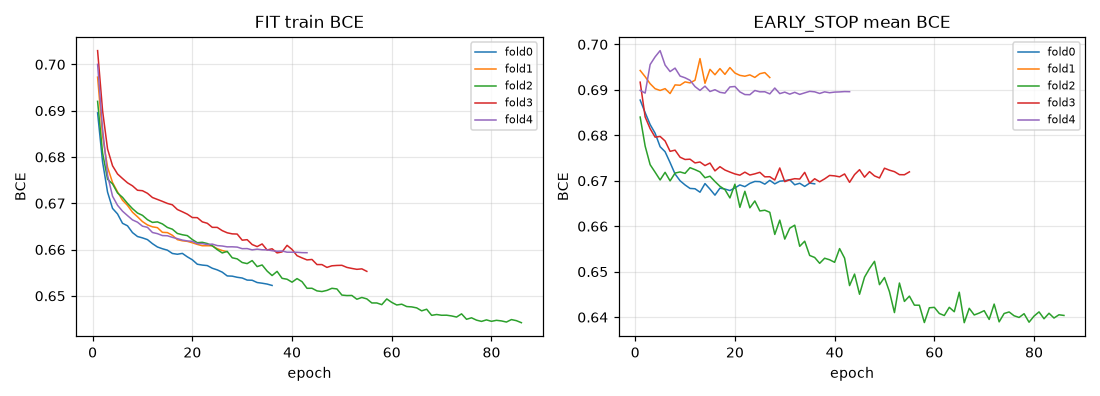

In [23]:
show_fig('reports/figures/p25f_training_curves.png')

## 23. Selected epoch per fold and the median rule

The final refit epoch count is the exact integer median of the five selected epochs.

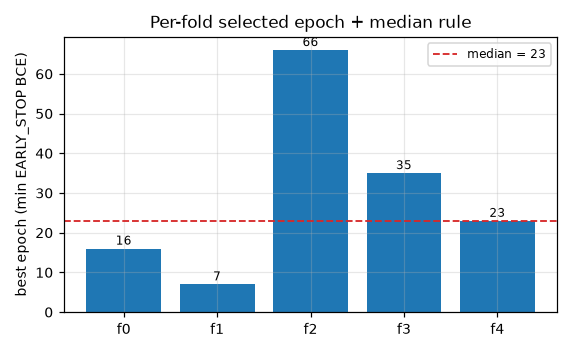

item,value
best_epoch_fold0,16
best_epoch_fold1,7
best_epoch_fold2,66
best_epoch_fold3,35
best_epoch_fold4,23
sorted_best_epochs,7 16 23 35 66
median_index,2
final_safety_epochs,23
final_seed,42


In [24]:
show_fig('reports/figures/p25f_best_epochs.png')
table(read_csv('reports/tables/phase25f_final_epoch_rule.csv'), 'Final epoch rule')

## 24. Training health

All histories are finite, best epochs are in range, and train BCE decreases in every fold.

In [25]:
health = read_json('reports/audits/phase25f_training_health.json')
print('best epochs:', health['best_epochs'], '| terminations:', health['terminations'])
table(read_csv('reports/tables/phase25f_training_health_summary.csv'), 'Training health checks')

best epochs: [16, 7, 66, 35, 23] | terminations: ['early_stop', 'early_stop', 'early_stop', 'early_stop', 'early_stop']


check,pass
fold0_history_nonempty,1
fold0_finite_losses,1
fold0_best_epoch_in_range,1
fold0_train_bce_decreased,1
fold0_epochs_monotone,1
fold1_history_nonempty,1
fold1_finite_losses,1
fold1_best_epoch_in_range,1
fold1_train_bce_decreased,1
fold1_epochs_monotone,1


## 25. Final epoch rule execution

`FINAL_SAFETY_EPOCHS = sorted(best_epoch_0..best_epoch_4)[2]`.

In [26]:
rule = read_json('reports/audits/phase25f_final_epoch_rule_execution.json')
print('best epochs:', rule['best_epochs_in_fold_order'])
print('sorted:', rule['sorted_best_epochs'], '| FINAL_SAFETY_EPOCHS:', rule['final_safety_epochs'])

best epochs: [16, 7, 66, 35, 23]
sorted: [7, 16, 23, 35, 66] | FINAL_SAFETY_EPOCHS: 23


## 26. Final all-DEV normalization

Statistics are re-fit on all 4957 `ROUTER_DEVELOPMENT` rows for the final refit.

In [27]:
fn = read_json('reports/audits/phase25f_final_normalization.json')
print('rows:', fn['rows'], '| source:', fn['statistics_source'], '| ddof:', fn['ddof'])
table(read_csv('reports/tables/phase25f_final_normalization_stats.csv'), 'Final normalization statistics')

rows: 4957 | source: all 4957 ROUTER_DEVELOPMENT rows | ddof: 0


feature_index,name,mu,sigma,is_constant
0,global_prob_mean,0.240778,0.068523,False
1,refined_prob_mean,0.240440,0.069142,False
2,mean_abs_prob_change,0.013552,0.012213,False
3,max_abs_prob_change,0.474824,0.152688,False
4,frac_abs_prob_change_ge_0p10,0.039925,0.038614,False
5,global_entropy_mean,0.071802,0.056141,False
6,refined_entropy_mean,0.083093,0.056034,False
7,global_foreground_fraction,0.239629,0.068515,False
8,refined_foreground_fraction,0.238670,0.068582,False
9,binary_xor_fraction,0.009288,0.011082,False


## 27. Final refit — complete epoch history

A fresh `BARRPostSafetyV1` is trained on all 4957 rows for exactly `FINAL_SAFETY_EPOCHS` epochs, with no validation and no early stopping. All 23 persisted epochs are rendered.

In [28]:
fc = read_json('reports/audits/phase25f_final_checkpoint_integrity.json')
print('final checkpoint:', fc['final_checkpoint'])
print('final safety epochs:', fc['final_safety_epochs'])
hf, clf = epoch_history('experiments/phase25f_barr_post_safety_v1_0_seed42/final/history.csv',
                        'experiments/phase25f_barr_post_safety_v1_0_seed42/final/run_complete.json',
                        23, expected_best=None, expected_term='fixed_epochs')
assert int(fc['final_safety_epochs']) == 23
assert int(hf['epoch'].iloc[-1]) == 23
# No validation exists for the final refit, so early_stop_bce is NaN by design (unused field).
print('final early_stop_bce all-NaN (by design, unused):',
      bool(hf['early_stop_bce'].isna().all()))
print('final train_bce finite:', bool(np.isfinite(hf['train_bce']).all()))
table(hf, 'Final refit - COMPLETE epoch history (all 23 rows; no truncation)')

final checkpoint: checkpoints/phase25f_barr_post_safety_v1_0_seed42/final/final.pt
final safety epochs: 23
final early_stop_bce all-NaN (by design, unused): True
final train_bce finite: True


epoch,train_bce,early_stop_bce,learning_rate,is_best,is_tie,bad_epochs,elapsed_seconds
1,0.682923,NaN,0.001,0,0,0,0.278
2,0.678028,NaN,0.001,0,0,0,0.407
3,0.674373,NaN,0.001,0,0,0,0.536
4,0.671982,NaN,0.001,0,0,0,0.647
5,0.670670,NaN,0.001,0,0,0,0.763
6,0.669347,NaN,0.001,0,0,0,0.865
7,0.668364,NaN,0.001,0,0,0,0.972
8,0.667481,NaN,0.001,0,0,0,1.084
9,0.666790,NaN,0.001,0,0,0,1.197
10,0.666447,NaN,0.001,0,0,0,1.301


## 28. Final checkpoint integrity

Parameter count, state-dict load, finite parameters and a synthetic forward pass.

In [29]:
table(pd.DataFrame(fc['checks'].items(), columns=['check','pass']), 'Final checkpoint integrity')
table(read_csv('reports/tables/phase25f_checkpoint_registry.csv'), 'Checkpoint registry')

check,pass
state_dict_loads,True
parameter_count_1217,True
finite_params,True
synthetic_inference_finite,True
output_is_raw_logit,True
epoch_equals_final_epochs,True
checkpoint_semantics_last_fixed_epoch,True
normalizer_persisted,True
no_early_stopping,True


run_id,kind,seed,path,sha256
phase25f_barr_post_safety_v1_0_seed42_cv_fold0,cv_best,54000,checkpoints/phase25f_barr_post_safety_v1_0_seed42/cv_fold0/best.pt,930a73207aaed2a5745a990d803df13925f4697689debb6e5bdb60270ac99871
phase25f_barr_post_safety_v1_0_seed42_cv_fold1,cv_best,54001,checkpoints/phase25f_barr_post_safety_v1_0_seed42/cv_fold1/best.pt,249f55897a5fa5258bfc5babd050c4448d501a94632c78d0ee6a31a52ef3819c
phase25f_barr_post_safety_v1_0_seed42_cv_fold2,cv_best,54002,checkpoints/phase25f_barr_post_safety_v1_0_seed42/cv_fold2/best.pt,b78dbd6969e92fb1caf859b3290a042face1933208f7dc3b881036c3b630ff15
phase25f_barr_post_safety_v1_0_seed42_cv_fold3,cv_best,54003,checkpoints/phase25f_barr_post_safety_v1_0_seed42/cv_fold3/best.pt,0d7bec864bcf7bbf2fcfc967351100be758fa9e770c3070407e2ec96e0620004
phase25f_barr_post_safety_v1_0_seed42_cv_fold4,cv_best,54004,checkpoints/phase25f_barr_post_safety_v1_0_seed42/cv_fold4/best.pt,75e15712381275e2f31052bd729344eb7e01b6d03c43f7e3f595407420b4fb22
phase25f_barr_post_safety_v1_0_seed42_final,final_refit,42,checkpoints/phase25f_barr_post_safety_v1_0_seed42/final/final.pt,eee9b97b9921e53fc07eac9281dce64ba518c6e1659916b97b0b3bec21ec6d2e


## 29. OOF safety prediction assembly

Each fold's frozen best checkpoint predicts once on that fold's OUTER_TARGET. The five folds union to exactly 4957 rows.

In [30]:
oof = read_csv('data_cache/phase25f_barr_post_safety_v1_0/phase25f_oof_safety_predictions.csv')
print('OOF rows:', len(oof), '| unique sample ids:', oof.sample_id.nunique())
table(oof.head(8), 'OOF safety predictions (head)')
table(read_csv('reports/tables/phase25f_oof_fold_coverage.csv'), 'OOF coverage by fold')

OOF rows: 4957 | unique sample ids: 4957


sample_id,feature_row_index,domain,task_id,safety_cv_fold,delta_dice,safety_target,safety_logit_oof,p_accept_oof,safety_decision_oof
0075dcb0e337263eff441a6979397143,0,BUSI,1,1,0.002521,1.0,0.106622,0.526630,ACCEPT_REFINEMENT
0076d60041fe324b4f16cd39458691a0,1,BUSI,1,0,-0.000128,0.0,0.253352,0.563001,ACCEPT_REFINEMENT
009868e61723f249e74bcfa14dc1aa30,2,BUSI,1,3,0.003329,1.0,0.146962,0.536674,ACCEPT_REFINEMENT
00a0c07e2060340164ebc605b3bf1746,3,BUSI,1,2,0.000514,1.0,0.434305,0.606901,ACCEPT_REFINEMENT
00f8ec946ef6890d99b06c50af6b431a,4,BUSI,1,1,0.000636,1.0,0.084138,0.521022,ACCEPT_REFINEMENT
011bacbfa3b9abcca28ddf92adf2ef9d,5,BUSI,1,1,-0.000364,0.0,0.132352,0.533040,ACCEPT_REFINEMENT
01c1bb8925ee26e9458e534dfb6388da,6,BUSI,1,4,0.001016,1.0,0.143238,0.535748,ACCEPT_REFINEMENT
01d6b05fe59f5c1f546b717ae93b8d51,7,BUSI,1,3,0.000634,1.0,0.273923,0.568056,ACCEPT_REFINEMENT


fold,n,n_accept,n_fallback,n_pos,n_neg
0,992,804,188,514,478
1,992,886,106,558,434
2,991,707,284,572,419
3,991,704,287,585,406
4,991,848,143,546,445


## 30. OOF integrity

Logits are finite, probabilities are the sigmoid of the logits, and decisions follow the fixed threshold `p_accept >= 0.50`.

In [31]:
oi = read_json('reports/audits/phase25f_oof_integrity.json')
print('decision counts:', oi['decision_counts'])
print('sigmoid matches logit:', oi['checks']['sigmoid_matches_logit'])
print('decisions match fixed threshold:', oi['checks']['decisions_match_fixed_threshold'])
table(read_csv('reports/tables/phase25f_oof_decision_distribution.csv'), 'OOF decisions by domain')

decision counts: {'ACCEPT_REFINEMENT': 3949, 'FALLBACK_GLOBAL': 1008}
sigmoid matches logit: True
decisions match fixed threshold: True


domain,n,n_accept,n_fallback,n_pos,n_neg
BUSI,512,456,56,277,235
ISIC,2173,1871,302,1196,977
KUB,1680,1278,402,1003,677
KVASIR,592,344,248,299,293


## 31. Prediction determinism

The full canonical fold-batched OOF inference is replayed 3x from the frozen checkpoints and compared to the stored logits.

In [32]:
det = read_json('reports/audits/phase25f_oof_prediction_determinism.json')
c = det['checks']
print('subset size:', c['subset_size'], '| per domain:', c['per_domain'])
print('full OOF max abs vs stored:', c['full_oof_max_abs_vs_stored'])
print('bit-identical to stored:', c['bit_identical_to_stored'], '| replays bit-identical:', c['replays_bit_identical'])

subset size: 64 | per domain: 16
full OOF max abs vs stored: 0.0
bit-identical to stored: True | replays bit-identical: True


## 32. OOF logit distribution

Separation of the ACCEPT (y=1) and FALLBACK (y=0) classes in OOF logit space.

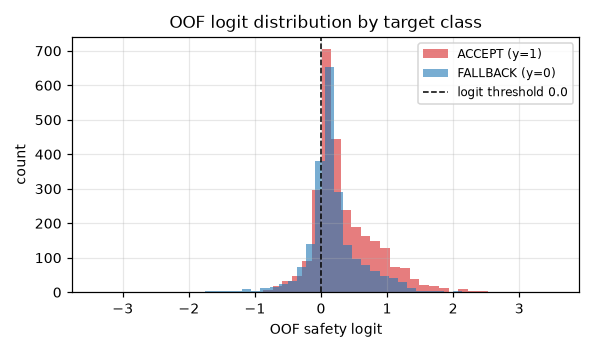

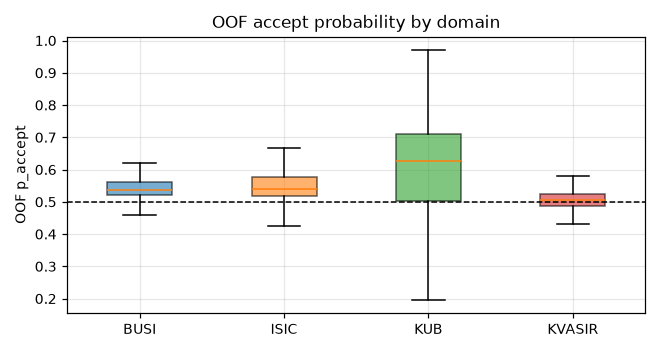

In [33]:
show_fig('reports/figures/p25f_oof_logit_distribution.png')
show_fig('reports/figures/p25f_oof_prob_by_domain.png')

## 33. Classifier-level metrics (overall)

Descriptive metrics for `S_omega` itself at the fixed 0.50 threshold. These are NOT segmentation results and NOT a preservation proof.

In [34]:
cmo = read_json('reports/audits/phase25f_classifier_metrics.json')
print('metric class:', cmo['metric_class'], '| threshold tuning:', cmo['threshold_tuning'])
table(read_csv('reports/tables/phase25f_classifier_metrics_overall.csv'), 'Classifier metrics - overall')

metric class: POST_SAFETY_TARGET_PREDICTION_METRICS | threshold tuning: False


metric,value
n,4957.000000
n_pos,2775.000000
n_neg,2182.000000
bce,0.669479
brier,0.238637
accuracy,0.571515
balanced_accuracy,0.536550
precision,0.582426
recall_sensitivity,0.828829
specificity,0.244271


## 34. Classifier-level metrics by domain

domain,n,n_pos,n_neg,bce,brier,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc,tp,fp,tn,fn
BUSI,512,277,235,0.692540,0.249760,0.525391,0.493302,0.537281,0.884477,0.102128,0.668486,0.497565,0.560682,245,211,24,32
ISIC,2173,1196,977,0.680608,0.244003,0.544869,0.508571,0.555318,0.868729,0.148414,0.677535,0.560299,0.624182,1039,832,145,157
KUB,1680,1003,677,0.642527,0.225635,0.627976,0.580413,0.647887,0.825523,0.335303,0.725997,0.639865,0.709753,828,450,227,175
KVASIR,592,299,293,0.685173,0.246218,0.548986,0.548170,0.546512,0.628763,0.467577,0.584759,0.555960,0.570246,188,156,137,111


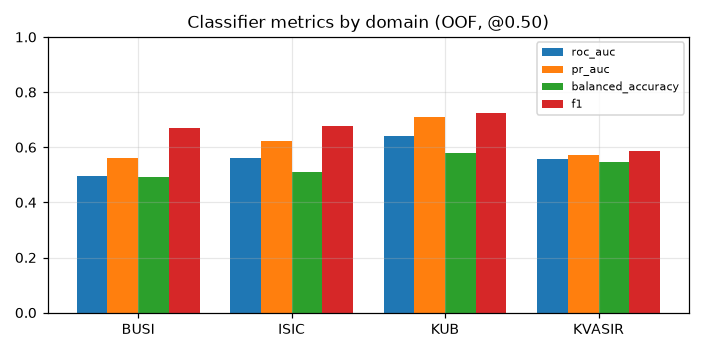

In [35]:
table(read_csv('reports/tables/phase25f_classifier_metrics_by_domain.csv'), 'Classifier metrics - by domain')
show_fig('reports/figures/p25f_metrics_by_domain.png')

## 35. Classifier-level metrics by CV fold

In [36]:
table(read_csv('reports/tables/phase25f_classifier_metrics_by_fold.csv'), 'Classifier metrics - by fold')

fold,n,n_pos,n_neg,bce,brier,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc,tp,fp,tn,fn
fold0,992,514,478,0.694958,0.250056,0.528226,0.516981,0.528607,0.826848,0.207113,0.644917,0.570342,0.590533,425,379,99,89
fold1,992,558,434,0.662991,0.235780,0.576613,0.527906,0.577878,0.917563,0.138249,0.709141,0.599272,0.673258,512,374,60,46
fold2,991,572,419,0.668802,0.238776,0.567104,0.534988,0.601132,0.743007,0.326969,0.664582,0.584133,0.675604,425,282,137,147
fold3,991,585,406,0.649668,0.229295,0.603431,0.567635,0.636364,0.765812,0.369458,0.695112,0.635321,0.715026,448,256,150,137
fold4,991,546,445,0.670960,0.239268,0.582240,0.546471,0.577830,0.897436,0.195506,0.703013,0.595502,0.640501,490,358,87,56


## 36. ROC and precision-recall curves

Classifier-level discrimination of the frozen `S_omega` on the 4957 development rows.

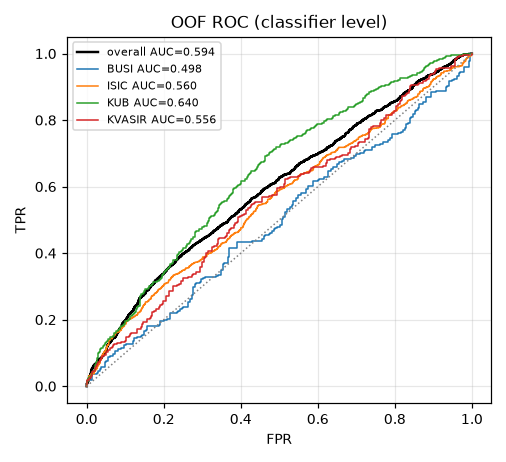

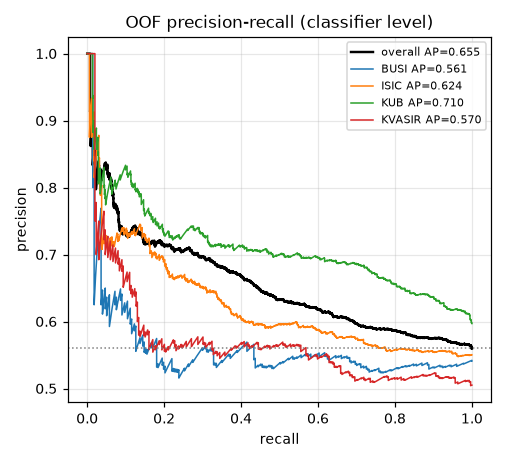

In [37]:
show_fig('reports/figures/p25f_roc_curves.png')
show_fig('reports/figures/p25f_pr_curves.png')

## 37. Confusion matrix at the fixed threshold

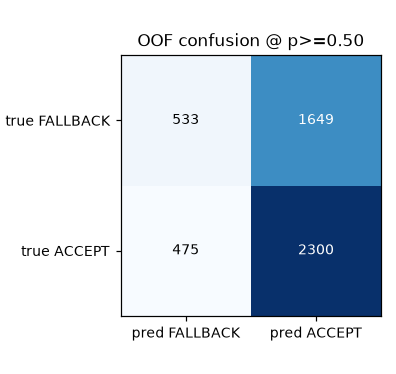

In [38]:
show_fig('reports/figures/p25f_confusion_matrix.png')

## 38. C9 post-safety state/decision artifact

C9 gates each frozen Phase25E C8 policy with the frozen `S_omega` decision. Only state/decision artifacts are constructed - no performance is evaluated.

In [39]:
c9 = read_json('reports/audits/phase25f_c9_decision_artifact.json')
print('comparator:', c9['comparator'], c9['comparator_name'])
print('C8 policies:', c9['c8_policy_count'], '| rows:', c9['rows'])
print('state counts:', c9['state_counts'])
table(read_csv('reports/tables/phase25f_c9_decision_summary.csv'), 'C9 state/decision summary per policy')

comparator: C9 POST_SAFETY
C8 policies: 20 | rows: 99140
state counts: {'STATE_B': 62464, 'STATE_C': 36676}


policy_id,lambda,budget,n,n_execute,n_skip,n_accept,n_reject
C8_lambda0.00_budget0.00,0.00,0.00,4957,0,4957,0,0
C8_lambda0.00_budget0.10,0.00,0.10,4957,495,4462,493,2
C8_lambda0.00_budget0.25,0.00,0.25,4957,1239,3718,1205,34
C8_lambda0.00_budget0.50,0.00,0.50,4957,2478,2479,2258,220
C8_lambda0.00_budget1.00,0.00,1.00,4957,4957,0,3949,1008
C8_lambda0.25_budget0.00,0.25,0.00,4957,0,4957,0,0
C8_lambda0.25_budget0.10,0.25,0.10,4957,495,4462,493,2
C8_lambda0.25_budget0.25,0.25,0.25,4957,1239,3718,1205,34
C8_lambda0.25_budget0.50,0.25,0.50,4957,2478,2479,2258,220
C8_lambda0.25_budget1.00,0.25,1.00,4957,4957,0,3949,1008


## 39. C9 state distribution

Across the 20 frozen C8 policies, how many samples fall into skip / accept / reject.

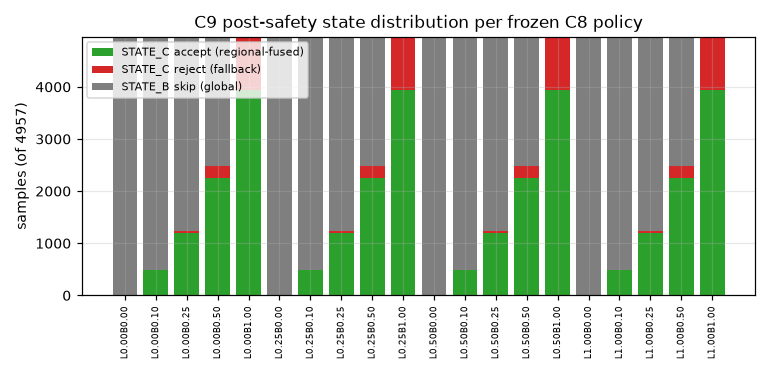

In [40]:
show_fig('reports/figures/p25f_c9_state_distribution.png')

## 40. Scope guards and locks

`ROUTER_HOLDOUT`, `VAL808` and `TEST` are never read. No A7/A8 segmentation comparison, no C8/C9 system-performance comparison, no preservation adjudication.

In [41]:
guard = read_json('reports/audits/phase25f_a7_a8_execution_guard.json')
table(read_csv('reports/tables/phase25f_scope_lock_summary.csv'), 'Scope lock summary')
print('A7/A8 evaluation owner:', guard['A7_A8_evaluation_owner'])
print('C8/C9 comparison owner:', guard['C8_C9_comparison_owner'])

item,value
router_holdout_reads,0
VAL808_reads,0
TEST_reads,0
A7_A8_segmentation_comparison_performed,0
C8_C9_system_performance_comparison_performed,0
preservation_adjudication_performed,0
threshold_tuned,0
new_budget_or_lambda_selected,0


A7/A8 evaluation owner: PHASE25G
C8/C9 comparison owner: PHASE25G


## 41. Conclusions (scoped)

- `BARRPostSafetyV1` was constructed exactly as frozen (1217 parameters, raw logit)
  and trained for exactly five frozen CV logical runs plus one all-DEV final refit
  (`FINAL_SAFETY_EPOCHS` = the integer median of the five selected epochs).
- **Every persisted epoch history is presented in full** (36 / 27 / 86 / 55 / 43 for
  the five CV folds; 23 for the final refit), with row counts, contiguous epoch
  sequences and canonical best epochs asserted from code against the frozen
  `run_complete.json` closures.
- 4957 OOF safety logits/probabilities/decisions were produced on `ROUTER_DEVELOPMENT`
  and are **bit-reproducible** (3x replay, max abs difference 0.0).
- Classifier-level metrics describe `S_omega` itself at the fixed 0.50 threshold; they
  are not segmentation results and not a preservation proof.
- The **C9 post-safety state/decision artifact** was constructed over the 20 frozen C8
  policies. No performance was evaluated.

**Handoff**: Phase25G owns A7-vs-A8, C8-vs-C9, preservation adjudication and the
integrated controlled development freeze. `ROUTER_HOLDOUT`, `VAL808` and `TEST` remain
unread; TEST is locked until Phase39.